# Process Window Scout (AM-PWS)

An agent that recommends **PBF-LB process windows** from the open-access literature and tells you which
published results to trust. Example request: *"316L, 200 W machine, 30 µm layers, density above 99.5 %"*.

This notebook is the whole project. Each part adds one piece of the agent, explains why it is built that
way, and tests it in the cells right below. Parts follow the course modules, so a concept is learned before
it is used.

**How to run:** kernel *Python 3.13 (CMU Agents)*, then *Kernel > Restart & Run All*. Every test cell prints
`ok` lines and stops with an error if something breaks. Slow steps (paper downloads, model calls) will save
their results in `data/` so a rerun is quick.

| Part | What it adds | Course module | Status |
|---|---|---|---|
| 1 | Deterministic tools: units, energy density, melt-pool band | 2 (tools) | built |
| 2 | Local model (Ollama) and a first ReAct agent with a trace log | 2 (ReAct) | next |
| 3 | Paper pipeline: OpenAlex search, PDF parsing, evidence store | 3 (RAG) | planned |
| 4 | Source check, consensus and conflict check | 3 and 4 | planned |
| 5 | Tree of Thought for outliers and window selection | 4 | planned |
| 6 | Reader and Checker agents, tools over MCP | 5 | planned |
| 7 | Guardrails, clarification step, engineer feedback memory | 6 | planned |
| 8 | Evaluation: prompt-only baseline vs agent | 7 | planned |

## 0. Setup

Paths and one small helper. `check()` is my test function: it prints `ok` when a condition holds and raises
an error when it does not, so *Restart & Run All* stops at the first broken piece.

In [1]:
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

# Project root = the repository folder (this notebook lives in notebooks/).
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
print("Project root:", ROOT)


def check(name, condition):
    # Tiny test helper: print ok, or stop the notebook with a clear message.
    assert condition, f"FAILED: {name}"
    print(f"  ok  {name}")

Project root: C:\Users\Chinmay.Phutela\Carnegie Capstone\process-window-scout


## Part 1. Deterministic tools

**Why tools first.** The agent will read numbers from papers and compare them. Language models are poor at
arithmetic (Module 1: numbers are split into tokens, and the model pattern-matches rather than calculates), so
the rule for this project is: *the model never does arithmetic*. Every number it reasons about comes from a
paper or from one of these plain Python functions.

Each tool follows the same contract (from Lab 2.2):
- typed inputs with the unit in the argument name (`power_W`, `scan_speed_mm_s`);
- a docstring that says what the tool does, when to use it, its inputs with units and an example. In
  Part 2 the agent framework reads the name, type hints and docstring to describe the tool to the model,
  so this text decides whether the model picks the right tool;
- it returns a dictionary: numbers for my code, plus a `summary` sentence that restates the inputs, units and
  result, which is what the agent will read;
- invalid input raises `ValueError` with a readable message. In Part 2 the agent loop will turn that message
  into an observation, so the model can correct itself instead of crashing;
- values that are legal but unusual for PBF-LB produce a warning in the summary. A scan speed of 0.8 "mm/s" is
  almost certainly 0.8 m/s, and I want that caught before it spoils a comparison.

The tools are tested here without any model. Only once they pass does an agent get to use them.

### 1.1 Unit conversion

Papers report scan speed in mm/s, m/s or even mm/min, and layer thickness in µm or mm. Before two papers can be
compared, everything goes to one set of units: **W, mm/s, µm**. The table maps each unit to its dimension and a
factor to SI, so a conversion is `value * factor_from / factor_to`. Asking for W to mm is refused rather than
silently producing nonsense.

In [2]:
# unit -> (dimension, factor to SI)
UNITS = {
    "W": ("power", 1.0), "kW": ("power", 1e3),
    "mm/s": ("speed", 1e-3), "m/s": ("speed", 1.0),
    "mm/min": ("speed", 1e-3 / 60), "m/min": ("speed", 1 / 60),
    "um": ("length", 1e-6), "µm": ("length", 1e-6), "μm": ("length", 1e-6),  # micro sign and Greek mu
    "mm": ("length", 1e-3), "m": ("length", 1.0),
    "J/mm3": ("energy density", 1e9), "J/m3": ("energy density", 1.0),
}


def convert_units(value: float, from_unit: str, to_unit: str) -> dict:
    """Convert a power, speed, length or energy density value from one unit to another.

    Use this whenever a paper reports a value in a different unit from the one needed for a comparison
    (project units are W, mm/s and µm). Do not convert units yourself.

    Args:
        value: the number to convert.
        from_unit: unit of the value, one of W, kW, mm/s, m/s, mm/min, m/min, um, µm, mm, m, J/mm3, J/m3.
        to_unit: unit wanted, same list; must measure the same quantity as from_unit.

    Example: convert_units(0.8, "m/s", "mm/s") gives 800 mm/s.
    Returns a dict with "value", "unit" and a "summary" sentence.
    """
    for u in (from_unit, to_unit):
        if u not in UNITS:
            raise ValueError(f"Unknown unit '{u}'. Known units: {', '.join(UNITS)}.")
    dim_from, f_from = UNITS[from_unit]
    dim_to, f_to = UNITS[to_unit]
    if dim_from != dim_to:
        raise ValueError(f"Cannot convert {dim_from} ({from_unit}) to {dim_to} ({to_unit}).")
    result = value * f_from / f_to
    return {
        "value": result,
        "unit": to_unit,
        "summary": f"{value:g} {from_unit} = {result:.6g} {to_unit} ({dim_from}).",
    }


print(convert_units(0.8, "m/s", "mm/s")["summary"])
print(convert_units(0.03, "mm", "µm")["summary"])

0.8 m/s = 800 mm/s (speed).
0.03 mm = 30 µm (length).


In [3]:
# Tests for convert_units
check("0.8 m/s is 800 mm/s", math.isclose(convert_units(0.8, "m/s", "mm/s")["value"], 800))
check("48 m/min is 800 mm/s", math.isclose(convert_units(48, "m/min", "mm/s")["value"], 800))
check("0.03 mm is 30 µm", math.isclose(convert_units(0.03, "mm", "µm")["value"], 30))
check("micro sign and Greek mu agree", convert_units(1, "mm", "µm")["value"] == convert_units(1, "mm", "μm")["value"])
check("0.4 kW is 400 W", math.isclose(convert_units(0.4, "kW", "W")["value"], 400))

for bad in [(1, "W", "mm"), (1, "furlong", "m")]:
    try:
        convert_units(*bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"{bad} raises: {e}", True)

  ok  0.8 m/s is 800 mm/s
  ok  48 m/min is 800 mm/s
  ok  0.03 mm is 30 µm
  ok  micro sign and Greek mu agree
  ok  0.4 kW is 400 W
  ok  (1, 'W', 'mm') raises: Cannot convert power (W) to length (mm).
  ok  (1, 'furlong', 'm') raises: Unknown unit 'furlong'. Known units: W, kW, mm/s, m/s, mm/min, m/min, um, µm, μm, mm, m, J/mm3, J/m3.


### 1.2 Energy density

Volumetric energy density is the number most papers use to summarise a parameter set:

$$E_v = \frac{P}{v \, h \, t} \quad [\mathrm{J/mm^3}]$$

with laser power $P$ (W), scan speed $v$ (mm/s), hatch spacing $h$ (mm) and layer thickness $t$ (mm). The tool
also reports linear energy density $P/v$ (J/mm).

$E_v$ is a coarse metric: two parameter sets with the same $E_v$ can give very different melt pools and
densities (Bertoli et al., 2017). The agent may use it to group papers, never to judge a result on its own,
and the summary says so.

The helper `_range_warnings` holds what I consider typical PBF-LB ranges. Values outside them are allowed but
flagged, mainly to catch unit mistakes.

In [4]:
# Typical PBF-LB ranges: outside these is legal but suspicious (often a unit mistake).
TYPICAL = {
    "power_W": (20, 1000),
    "scan_speed_mm_s": (50, 5000),
    "hatch_um": (20, 300),
    "layer_um": (10, 150),
}


def _validate(**inputs) -> list[str]:
    # Raise on non-positive values; return warnings for values outside typical PBF-LB ranges.
    warnings = []
    for name, value in inputs.items():
        if value is None or not value > 0:
            raise ValueError(f"{name} must be a positive number, got {value!r}.")
        lo, hi = TYPICAL[name]
        if not lo <= value <= hi:
            warnings.append(f"{name} = {value:g} is outside the typical PBF-LB range {lo:g} to {hi:g}; check the units.")
    return warnings


def energy_density(power_W: float, scan_speed_mm_s: float, hatch_um: float, layer_um: float) -> dict:
    """Volumetric energy density E_v = P/(v*h*t) in J/mm³ and linear energy density P/v in J/mm.

    Use this when a paper gives laser power, scan speed, hatch spacing and layer thickness and you need
    its energy density, for example to group papers. E_v is a coarse metric: never judge a result on
    E_v alone.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        hatch_um: hatch spacing in µm.
        layer_um: layer thickness in µm.

    Example: energy_density(200, 800, 100, 30) gives E_v = 83.3 J/mm³.
    Returns a dict with "ved_J_mm3", "led_J_mm", "warnings" and a "summary" sentence.
    """
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s, hatch_um=hatch_um, layer_um=layer_um)
    ved = power_W / (scan_speed_mm_s * (hatch_um / 1000) * (layer_um / 1000))
    led = power_W / scan_speed_mm_s
    summary = (
        f"For P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, h = {hatch_um:g} µm, t = {layer_um:g} µm: "
        f"volumetric energy density E_v = P/(v*h*t) = {ved:.1f} J/mm³; linear energy density P/v = {led:.3f} J/mm. "
        "E_v is a coarse metric: equal E_v does not mean an equal melt pool or density."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"ved_J_mm3": ved, "led_J_mm": led, "warnings": warnings, "summary": summary}


print(energy_density(200, 800, 100, 30)["summary"])

For P = 200 W, v = 800 mm/s, h = 100 µm, t = 30 µm: volumetric energy density E_v = P/(v*h*t) = 83.3 J/mm³; linear energy density P/v = 0.250 J/mm. E_v is a coarse metric: equal E_v does not mean an equal melt pool or density.


In [5]:
# Tests for energy_density
r = energy_density(200, 800, 100, 30)
check("200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³", math.isclose(r["ved_J_mm3"], 83.333, rel_tol=1e-4))
check("linear energy density 0.25 J/mm", math.isclose(r["led_J_mm"], 0.25))
check("no warnings for a typical set", r["warnings"] == [])
check("doubling speed halves E_v", math.isclose(energy_density(200, 1600, 100, 30)["ved_J_mm3"], r["ved_J_mm3"] / 2))

# A speed given in m/s by mistake: allowed, but flagged in the summary the agent reads.
r_bad = energy_density(200, 0.8, 100, 30)
check("0.8 mm/s is flagged as a likely unit mistake", "scan_speed_mm_s" in r_bad["summary"] and r_bad["warnings"])

for bad in [dict(power_W=0, scan_speed_mm_s=800, hatch_um=100, layer_um=30),
            dict(power_W=200, scan_speed_mm_s=-5, hatch_um=100, layer_um=30)]:
    try:
        energy_density(**bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  200 W, 800 mm/s, 100 µm, 30 µm gives 83.3 J/mm³
  ok  linear energy density 0.25 J/mm
  ok  no warnings for a typical set
  ok  doubling speed halves E_v
  ok  0.8 mm/s is flagged as a likely unit mistake
  ok  raises: power_W must be a positive number, got 0.
  ok  raises: scan_speed_mm_s must be a positive number, got -5.


### 1.3 Melt-pool band (physics as weak evidence)

This is the tool that lets the agent *generate new data* rather than only read it. It estimates melt-pool width
and depth with the **Rosenthal** solution for a moving point heat source on a semi-infinite body. In the frame
moving with the laser (position $\xi$ along the scan direction, $\xi < 0$ behind the laser, $R$ the distance
from the source):

$$T - T_0 = \frac{A P}{2 \pi k R} \exp\left(-\frac{v (\xi + R)}{2 \alpha}\right), \qquad \alpha = \frac{k}{\rho c_p}$$

The melt pool is the region where $T \ge T_m$. For a given $\xi$ the right-hand side falls steadily with $R$,
so the melt boundary has a closed form through the Lambert W function. With $b = v / 2\alpha$ and
$C = A P / (2 \pi k (T_m - T_0))$:

$$R_m(\xi) = \frac{1}{b} W_0\left(b \, C \, e^{-b \xi}\right), \qquad r(\xi) = \sqrt{R_m^2 - \xi^2}$$

The pool runs from the rear tip at $\xi = -C$ to the front tip at $\xi_f = W_0(2 b C)/(2b)$. Width is
$2 \max r$. Because only $R$ appears in the solution, the cross-section is a half circle: **depth = width / 2**.

**Why a band, and why weak evidence.** Rosenthal ignores latent heat, Marangoni flow, keyholing, the powder
layer and temperature-dependent properties, and the absorptivity $A$ is rarely known. I run it at
$A$ = 0.3, 0.5 and 0.7 and treat the spread as an uncertainty band. In Part 4 a paper is flagged as an outlier
only if the consensus of other papers *and the whole band* disagree with it. In keyhole conditions the real
depth will be well above this estimate, so a too-shallow band is expected there and is not a contradiction.

**Material properties** are averages between room temperature and melting. They are approximate (after Mills,
2002) and are the first thing to revisit if the band looks off.

In [6]:
# Approximate 316L properties, averaged between room temperature and melting (after Mills, 2002).
MATERIALS = {
    "316L": {
        "k_W_mK": 22.0,      # thermal conductivity (about 14 at room temperature, about 30 near melting)
        "rho_kg_m3": 7800.0, # density
        "cp_J_kgK": 600.0,   # specific heat (about 500 to 720 over the range)
        "T_melt_K": 1700.0,  # between solidus (about 1658 K) and liquidus (about 1723 K)
        "T0_K": 300.0,       # build plate / powder bed temperature, no preheat
    },
}


def _rosenthal_pool(power_W, scan_speed_mm_s, absorptivity, mat):
    # Melt-pool width, depth and length (µm) from the Rosenthal point-source solution.
    k, rho, cp = mat["k_W_mK"], mat["rho_kg_m3"], mat["cp_J_kgK"]
    v = scan_speed_mm_s / 1000                      # m/s
    alpha = k / (rho * cp)                          # thermal diffusivity, m²/s
    b = v / (2 * alpha)                             # 1/m
    C = absorptivity * power_W / (2 * math.pi * k * (mat["T_melt_K"] - mat["T0_K"]))  # m

    xi_rear = -C                                    # rear tip of the pool
    xi_front = lambertw(2 * b * C).real / (2 * b)   # front tip of the pool
    xi = np.linspace(xi_rear, xi_front, 4001)
    R_m = lambertw(b * C * np.exp(-b * xi)).real / b   # melt boundary distance at each xi
    r = np.sqrt(np.clip(R_m**2 - xi**2, 0, None))      # half-width of the pool at each xi

    width = 2 * r.max()
    return {"width_um": width * 1e6, "depth_um": width / 2 * 1e6, "length_um": (xi_front - xi_rear) * 1e6}


def melt_pool_band(power_W: float, scan_speed_mm_s: float, material: str = "316L",
                   absorptivities: tuple = (0.3, 0.5, 0.7)) -> dict:
    """Estimated melt-pool width and depth (µm) from the Rosenthal model, as a band over absorptivity.

    Use this to see whether physics supports or contradicts a reported result at a given laser power and
    scan speed, for example whether the melt pool is likely deeper than the layer. The result is weak
    evidence: the model ignores fluid flow and keyholing, so treat the band as a rough range, not a check.

    Args:
        power_W: laser power in W.
        scan_speed_mm_s: scan speed in mm/s (convert m/s first).
        material: alloy name; only "316L" is available.
        absorptivities: laser absorptivities to try, each between 0 and 1 (default 0.3, 0.5, 0.7).

    Example: melt_pool_band(200, 800) gives width about 101 to 156 µm, depth about 51 to 78 µm.
    Returns a dict with "material", "band" (one row per absorptivity), "warnings" and a "summary" sentence.
    """
    if material not in MATERIALS:
        raise ValueError(f"No properties for material '{material}'. Available: {', '.join(MATERIALS)}.")
    for a in absorptivities:
        if not 0 < a <= 1:
            raise ValueError(f"Absorptivity must be between 0 and 1, got {a}.")
    warnings = _validate(power_W=power_W, scan_speed_mm_s=scan_speed_mm_s)

    rows = [{"absorptivity": a, **_rosenthal_pool(power_W, scan_speed_mm_s, a, MATERIALS[material])}
            for a in absorptivities]
    w = [row["width_um"] for row in rows]
    d = [row["depth_um"] for row in rows]
    summary = (
        f"Rosenthal estimate for {material} at P = {power_W:g} W, v = {scan_speed_mm_s:g} mm/s, "
        f"absorptivity {min(absorptivities):g} to {max(absorptivities):g}: melt-pool width {min(w):.0f} to {max(w):.0f} µm, "
        f"depth {min(d):.0f} to {max(d):.0f} µm. Weak evidence: the model ignores fluid flow and keyholing, "
        "so real depth can be much larger at high energy input."
    )
    if warnings:
        summary += " Warning: " + " ".join(warnings)
    return {"material": material, "band": rows, "warnings": warnings, "summary": summary}


band = melt_pool_band(200, 800)
print(band["summary"])
for row in band["band"]:
    print(f"  A = {row['absorptivity']}: width {row['width_um']:.0f} µm, depth {row['depth_um']:.0f} µm, length {row['length_um']:.0f} µm")

Rosenthal estimate for 316L at P = 200 W, v = 800 mm/s, absorptivity 0.3 to 0.7: melt-pool width 101 to 156 µm, depth 51 to 78 µm. Weak evidence: the model ignores fluid flow and keyholing, so real depth can be much larger at high energy input.
  A = 0.3: width 101 µm, depth 51 µm, length 327 µm
  A = 0.5: width 132 µm, depth 66 µm, length 536 µm
  A = 0.7: width 156 µm, depth 78 µm, length 744 µm


**How do I know the solver is right?** Three kinds of test:
1. *Physical trends:* the pool grows with power and absorptivity and shrinks with speed.
2. *Built-in geometry:* depth is exactly half the width.
3. *An independent formula:* at high speed the Rosenthal width tends to
   $W \approx \sqrt{\dfrac{8 A P}{\pi e \, \rho c_p v (T_m - T_0)}}$, which I derived separately from the same
   equation. My numerical result should approach it as speed increases, and stay within a few percent at
   typical PBF-LB speeds.

In [7]:
# Tests for melt_pool_band
def width(P, v, A=0.5):
    return _rosenthal_pool(P, v, A, MATERIALS["316L"])["width_um"]

def width_high_speed(P, v, A=0.5, m=MATERIALS["316L"]):
    dT = m["T_melt_K"] - m["T0_K"]
    return math.sqrt(8 * A * P / (math.pi * math.e * m["rho_kg_m3"] * m["cp_J_kgK"] * (v / 1000) * dT)) * 1e6

check("wider at higher power", width(300, 800) > width(200, 800))
check("narrower at higher speed", width(200, 1200) < width(200, 800))
check("wider at higher absorptivity", width(200, 800, 0.7) > width(200, 800, 0.3))

pool = _rosenthal_pool(200, 800, 0.5, MATERIALS["316L"])
check("depth is half the width", math.isclose(pool["depth_um"], pool["width_um"] / 2))

for P, v in [(200, 800), (370, 1500), (200, 3000)]:
    ratio = width(P, v) / width_high_speed(P, v)
    check(f"P = {P} W, v = {v} mm/s: within 5 % of the high-speed formula (ratio {ratio:.3f})", abs(ratio - 1) < 0.05)
check("closer to the formula at higher speed", abs(width(200, 3000) / width_high_speed(200, 3000) - 1)
      < abs(width(200, 400) / width_high_speed(200, 400) - 1))

b = melt_pool_band(200, 800)
check("band has three absorptivities", [row["absorptivity"] for row in b["band"]] == [0.3, 0.5, 0.7])
check("summary states inputs and units", "200 W" in b["summary"] and "800 mm/s" in b["summary"] and "µm" in b["summary"])
for bad in [dict(material="Ti64"), dict(absorptivities=(0.5, 1.5))]:
    try:
        melt_pool_band(200, 800, **bad)
        check(f"{bad} should raise", False)
    except ValueError as e:
        check(f"raises: {e}", True)

  ok  wider at higher power
  ok  narrower at higher speed
  ok  wider at higher absorptivity
  ok  depth is half the width
  ok  P = 200 W, v = 800 mm/s: within 5 % of the high-speed formula (ratio 0.985)
  ok  P = 370 W, v = 1500 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  P = 200 W, v = 3000 mm/s: within 5 % of the high-speed formula (ratio 0.996)
  ok  closer to the formula at higher speed
  ok  band has three absorptivities
  ok  summary states inputs and units
  ok  raises: No properties for material 'Ti64'. Available: 316L.
  ok  raises: Absorptivity must be between 0 and 1, got 1.5.


**Demo: the band across scan speeds.** The shaded area is what the agent will later hold a paper's reported
result against. At 30 µm layers, for example, a depth band that sits well above the layer thickness says the
physics does not argue against full fusion; it does not prove it.

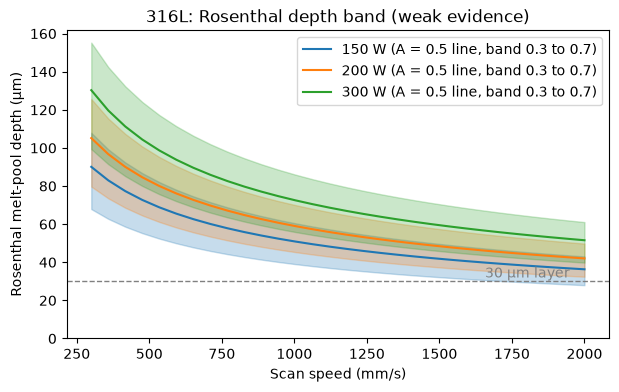

In [8]:
speeds = np.linspace(300, 2000, 30)
fig, ax = plt.subplots(figsize=(7, 4))
for P, colour in [(150, "tab:blue"), (200, "tab:orange"), (300, "tab:green")]:
    bands = [melt_pool_band(P, v)["band"] for v in speeds]
    lo = [b_[0]["depth_um"] for b_ in bands]
    mid = [b_[1]["depth_um"] for b_ in bands]
    hi = [b_[2]["depth_um"] for b_ in bands]
    ax.fill_between(speeds, lo, hi, color=colour, alpha=0.25)
    ax.plot(speeds, mid, color=colour, label=f"{P} W (A = 0.5 line, band 0.3 to 0.7)")
ax.axhline(30, color="grey", ls="--", lw=1)
ax.text(1950, 32, "30 µm layer", ha="right", color="grey")
ax.set_ylim(0, None)
ax.set_xlabel("Scan speed (mm/s)")
ax.set_ylabel("Rosenthal melt-pool depth (µm)")
ax.set_title("316L: Rosenthal depth band (weak evidence)")
ax.legend()
plt.show()

### Part 1 summary

- Three tested tools: `convert_units`, `energy_density`, `melt_pool_band`. None needs a model.
- Each returns numbers for code and a sentence with inputs and units for the agent.
- Bad inputs raise readable errors; suspicious ones are flagged in the sentence.
- The melt-pool solver agrees with an independent high-speed formula, but its output stays weak evidence.

**Next:** Part 2 connects the language model; Part 3 gives it a library of papers to search.

## Part 2 (first slice). Connecting the language model

The agent's reasoning comes from **GLM-5.2**, an open-weight model served on a vLLM server with an
OpenAI-compatible API. That means the standard `openai` Python client can talk to it; only the address and
model name change.

- The address, model name and key live in `.env` (never committed). The notebook only reads them.
- **Thinking mode is on.** GLM-5.2 writes its reasoning first and its answer second. `ask_llm()` returns both,
  and the agent will print the reasoning at every step, because seeing *why* it chose something is the main
  way I will debug it.
- Reasoning uses many tokens (in a test, 270 of 279 output tokens), so `max_tokens` is generous; too small a
  limit returns an empty answer.

The full ReAct loop (the model choosing tools by itself) is the second slice of Part 2. For Checkpoint 3.1
two plain calls are enough: one without and one with retrieved passages.

In [9]:
import os
import json
import time
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ROOT / ".env")
LLM_MODEL = os.environ.get("LLM_MODEL", "")
llm = OpenAI(base_url=os.environ.get("LLM_BASE_URL"), api_key=os.environ.get("LLM_API_KEY") or "EMPTY",
             timeout=300, max_retries=1)


def llm_available() -> bool:
    # True when the endpoint answers. Off the office network it does not, and the LLM cells skip politely.
    try:
        llm.with_options(timeout=10, max_retries=0).models.list()
        return True
    except Exception as e:
        print(f"LLM endpoint not reachable ({type(e).__name__}). LLM cells will be skipped.")
        return False


def ask_llm(messages, max_tokens=6000, show_reasoning=True):
    """Send a chat to GLM-5.2 with thinking on. Returns (reasoning, answer)."""
    t0 = time.time()
    r = llm.chat.completions.create(model=LLM_MODEL, messages=messages, max_tokens=max_tokens)
    msg = r.choices[0].message
    extra = msg.model_extra or {}
    reasoning = getattr(msg, "reasoning", None) or extra.get("reasoning") or extra.get("reasoning_content") or ""
    answer = msg.content or ""
    if show_reasoning and reasoning:
        print(f"--- reasoning ({len(reasoning.split())} words) ---\n{reasoning}\n")
    print(f"[{time.time() - t0:.0f} s, {r.usage.completion_tokens} output tokens]")
    return reasoning, answer


LLM_OK = llm_available()
print("Model:", LLM_MODEL or "(not set)", "| reachable:", LLM_OK)

LLM endpoint not reachable (APIConnectionError). LLM cells will be skipped.
Model: GLM-5.2 | reachable: False


In [10]:
# Test: one short call (skipped off-network)
if LLM_OK:
    reasoning, answer = ask_llm([{"role": "user", "content": "In one sentence, what is volumetric energy density in PBF-LB?"}],
                                max_tokens=2000)
    print("answer:", answer)
    check("the model returned an answer", len(answer) > 10)
    check("the model returned its reasoning", len(reasoning) > 10)

## Part 3a. Retrieval: a searchable library of papers

**Why retrieval at all.** The facts this agent needs (which study used which power, speed and layer thickness,
and what density it measured) are in papers, not in the model. GLM-5.2 could take a whole stack of papers in
one prompt, but that context would be re-sent at every agent step, facts in the middle of a long context are
easily missed (Module 2), and the source check needs the exact passage behind every value. So the agent
retrieves only the few passages it needs.

Retrieval happens at three levels:

| Level | Question | Mechanism |
|---|---|---|
| Papers | Which open-access 316L studies exist? | Europe PMC search API |
| Passages | Where in them are the parameters and densities? | Semantic search over chunks (this part) |
| Numbers | Which extracted values match given settings? | SQL over an evidence table (Part 3b) |

**Data source.** I first used OpenAlex and downloaded PDFs, but most publishers block automated downloads
(HTTP 403 on 23 of 25 papers). **Europe PMC** serves the full text of open-access papers through an official
API as structured XML, with tables intact. So citations point to a **section or table** rather than a page,
which is easier to check by hand anyway.

In [11]:
import re
import xml.etree.ElementTree as ET
import requests

EPMC = "https://www.ebi.ac.uk/europepmc/webservices/rest"
PAPERS = DATA / "papers"
PAPERS.mkdir(exist_ok=True)


def search_papers(query: str, n: int = 30) -> list[dict]:
    """Search Europe PMC and return paper records (pmcid, doi, title, year, journal)."""
    r = requests.get(f"{EPMC}/search", params={"query": query, "format": "json", "pageSize": n,
                                                "resultType": "lite"}, timeout=30)
    r.raise_for_status()
    return [{"pmcid": w["pmcid"], "doi": w.get("doi", ""), "title": w["title"], "year": w.get("pubYear"),
             "journal": w.get("journalTitle", "")} for w in r.json()["resultList"]["result"] if w.get("pmcid")]


def fetch_fulltext(pmcid: str) -> Path:
    """Download the full-text XML once and cache it in data/papers/."""
    path = PAPERS / f"{pmcid}.xml"
    if not path.exists():
        r = requests.get(f"{EPMC}/{pmcid}/fullTextXML", timeout=60)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

### Reading a paper and labelling its alloy

The XML gives the title, DOI, section texts and every table. Tables are turned into plain rows
(`cell | cell | cell`) so that numbers stay next to their column headers and units.

**Alloy label.** Every chunk will carry the paper's alloy, so a search for 316L can exclude other alloys. A
paper about 25CrMo4 steel may still *mention* 316L for comparison, so the label comes from the **title**
first, and only falls back to counting mentions in the text.

In [12]:
GRADES = {  # name -> regular expression
    "316L": r"316\s?L", "304L": r"\b304L?\b", "17-4PH": r"17-4\s?PH", "25CrMo4": r"25CrMo4",
    "AlSi10Mg": r"AlSi10Mg", "Ti-6Al-4V": r"Ti-?6Al-?4V", "IN718": r"(IN|Inconel\s?)718",
    "H13": r"\bH13\b", "maraging": r"[Mm]araging",
}


def text_of(el) -> str:
    return re.sub(r"\s+", " ", "".join(el.itertext())).strip() if el is not None else ""


def detect_alloy(title: str, full_text: str) -> str:
    # Title first: it names the alloy the paper is actually about.
    in_title = [g for g, rx in GRADES.items() if re.search(rx, title)]
    if in_title:
        return in_title[0]
    counts = {g: len(re.findall(rx, full_text)) for g, rx in GRADES.items()}
    return max(counts, key=counts.get) if max(counts.values()) else "unknown"


def parse_paper(path: Path) -> dict:
    """Parse a Europe PMC JATS XML file into title, doi, sections, tables and alloy."""
    root = ET.parse(path).getroot()
    title = text_of(root.find(".//article-title"))
    doi = text_of(root.find(".//article-id[@pub-id-type='doi']"))
    tables = []
    for tw in root.iter("table-wrap"):  # tables sit in <body> or <floats-group>
        head = f"{text_of(tw.find('label'))} {text_of(tw.find('caption'))}".strip()
        rows = [" | ".join(text_of(c) for c in tr if c.tag in ("td", "th")) for tr in tw.iter("tr")]
        rows = [r for r in rows if r.strip(" |")]
        if rows:
            tables.append({"label": head, "text": "\n".join(rows)})
    sections = []
    body = root.find(".//body")
    if body is not None:
        for sec in body.findall("sec"):
            paras = [text_of(p) for p in sec.iter("p")]
            sections.append({"title": text_of(sec.find("title")) or "Body", "text": " ".join(p for p in paras if p)})
    full = " ".join(s["text"] for s in sections) + " " + " ".join(t["text"] for t in tables)
    return {"title": title, "doi": doi, "sections": sections, "tables": tables, "alloy": detect_alloy(title, full)}


def has_parameter_table(paper: dict) -> bool:
    # At least one table that mentions power, speed and density or porosity.
    for t in paper["tables"]:
        s = (t["label"] + " " + t["text"]).lower()
        if "power" in s and ("speed" in s or "velocity" in s or "mm/s" in s) and ("density" in s or "porosity" in s):
            return True
    return False

### Choosing the papers

The search asks Europe PMC for open-access, CC BY licensed 316L PBF-LB papers that mention density and scan
speed. A paper is **kept** if its alloy label is 316L and it has at least one parameter table. For this first
slice I keep **5 papers**, plus **one deliberate distractor**: the first paper about a *different* alloy that
also has a parameter table. The distractor is there to test the alloy filter (the failure mode in 3a.5).

The selection is saved, so later runs reuse the same papers even if the search results change.

In [13]:
SELECTION = PAPERS / "selection.json"
QUERY = ('("316L") AND ("laser powder bed fusion" OR "selective laser melting") AND '
         '("relative density" OR "porosity") AND ("scan speed" OR "scanning speed") AND '
         'OPEN_ACCESS:y AND HAS_FT:y AND LICENSE:"cc by"')

if SELECTION.exists():
    selection = json.loads(SELECTION.read_text(encoding="utf-8"))
else:
    selection, distractor = [], None
    for hit in search_papers(QUERY, n=40):
        paper = parse_paper(fetch_fulltext(hit["pmcid"]))
        if not has_parameter_table(paper):
            continue
        if paper["alloy"] == "316L" and len(selection) < 5:
            selection.append({**hit, "alloy": "316L", "role": "source"})
        elif paper["alloy"] not in ("316L", "unknown") and distractor is None:
            distractor = {**hit, "alloy": paper["alloy"], "role": "distractor"}
        if len(selection) == 5 and distractor:
            break
    selection.append(distractor)
    SELECTION.write_text(json.dumps(selection, indent=1), encoding="utf-8")

papers = {s["pmcid"]: parse_paper(fetch_fulltext(s["pmcid"])) for s in selection}
for s in selection:
    p = papers[s["pmcid"]]
    print(f"{s['role']:<10} {s['pmcid']}  {p['alloy']:<8} {len(p['tables']):>2} tables  {s['year']}  {p['title'][:70]}")

source     PMC13073740  316L      5 tables  2026  A Lattice Boltzmann Thermal Model for Predicting Melt Pool Geometry in


source     PMC12735063  316L      5 tables  2025  Role of Laser Powder Bed Fusion Process Factors in Determining the Por
source     PMC13208960  316L      3 tables  2026  Novel Design in Venturi-Type Nozzle by Selective Laser Melting for Enh
source     PMC12387571  316L      4 tables  2025  Manufacturing, Microstructure, and Mechanics of 316L SS Biomaterials b
source     PMC12194911  316L     18 tables  2025  A Review of Optimization of Additively Manufactured 316/316L Stainless
distractor PMC12693020  25CrMo4   8 tables  2025  Laser Powder Bed Fusion of 25CrMo4 Steel: Effect of Process Parameters


In [14]:
# Tests for the paper library
check("5 source papers and 1 distractor", [s["role"] for s in selection].count("source") == 5
      and [s["role"] for s in selection].count("distractor") == 1)
check("every source paper is labelled 316L", all(papers[s["pmcid"]]["alloy"] == "316L" for s in selection if s["role"] == "source"))
check("the distractor is another alloy", all(papers[s["pmcid"]]["alloy"] != "316L" for s in selection if s["role"] == "distractor"))
check("every paper has a parameter table", all(has_parameter_table(p) for p in papers.values()))
check("every paper has a DOI", all(p["doi"] for p in papers.values()))

  ok  5 source papers and 1 distractor
  ok  every source paper is labelled 316L
  ok  the distractor is another alloy
  ok  every paper has a parameter table
  ok  every paper has a DOI


### 3a.3 Chunking

- **Text:** each section is cut into windows of about **250 words with 50 words of overlap**, so a sentence cut
  at a boundary still appears whole in the next chunk. Each chunk keeps its section title.
- **Tables:** **never split**. A table row means nothing without its header and units, and process parameters
  are almost always reported in tables. Each table becomes one chunk, caption included.
- Every chunk carries metadata: paper ID, DOI, title, **alloy**, where it came from (section or table) and kind.

Smaller chunks than the lecture's 800 to 1000 tokens, because the answer is often a single table row and the
citation should point to one place.

In [15]:
def chunk_paper(pmcid: str, paper: dict, size: int = 250, overlap: int = 50) -> list[dict]:
    """Split a parsed paper into text chunks (overlapping word windows) and whole-table chunks."""
    meta = {"pmcid": pmcid, "doi": paper["doi"], "title": paper["title"][:200], "alloy": paper["alloy"]}
    chunks = []
    for sec in paper["sections"]:
        words = sec["text"].split()
        for start in range(0, max(len(words) - overlap, 1), size - overlap):
            piece = " ".join(words[start:start + size])
            if len(piece.split()) >= 30:  # skip scraps
                chunks.append({"text": piece, **meta, "where": sec["title"][:80], "kind": "text"})
    for t in paper["tables"]:
        chunks.append({"text": f"{t['label']}\n{t['text']}", **meta, "where": (t["label"] or "Table")[:80], "kind": "table"})
    for i, c in enumerate(chunks):
        c["id"] = f"{pmcid}-{i:03d}"
    return chunks


chunks = [c for pmcid, p in papers.items() for c in chunk_paper(pmcid, p)]
n_tables = sum(c["kind"] == "table" for c in chunks)
print(f"{len(chunks)} chunks: {len(chunks) - n_tables} text, {n_tables} tables")

328 chunks: 285 text, 43 tables


In [16]:
# Tests for chunking
text_chunks = [c for c in chunks if c["kind"] == "text"]
check("text chunks are at most 250 words", max(len(c["text"].split()) for c in text_chunks) <= 250)
check("one chunk per table (tables are never split)", n_tables == sum(len(p["tables"]) for p in papers.values()))
check("chunk ids are unique", len({c["id"] for c in chunks}) == len(chunks))
check("every chunk knows its paper, alloy and place", all(c["pmcid"] and c["alloy"] and c["where"] for c in chunks))
first = chunk_paper("x", {"doi": "d", "title": "t", "alloy": "316L", "tables": [],
                          "sections": [{"title": "S", "text": " ".join(f"w{i}" for i in range(400))}]})
check("consecutive text chunks overlap by 50 words", first[0]["text"].split()[-50:] == first[1]["text"].split()[:50])

  ok  text chunks are at most 250 words
  ok  one chunk per table (tables are never split)
  ok  chunk ids are unique
  ok  every chunk knows its paper, alloy and place
  ok  consecutive text chunks overlap by 50 words


### 3a.4 Embeddings and the vector database

- **Embedding model: Qwen3-Embedding-0.6B**, run locally on the laptop GPU (about 1.2 GB). The lab used
  all-MiniLM-L6-v2, but MiniLM silently cuts every input at 256 tokens, which would chop the longer tables.
  Qwen3 reads up to 32k tokens. Questions are encoded with the model's `query` prompt; chunks without one,
  as the model card recommends.
- **Vector database: ChromaDB**, stored in `data/chroma/`. Each chunk is stored with its vector and metadata,
  so a search can be **filtered by alloy**. Cosine similarity is used.
- Embedding all chunks takes about a minute the first time; afterwards the database is reused.

In [17]:
import torch
import chromadb
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
_device = "cuda" if torch.cuda.is_available() else "cpu"
_kw = {"model_kwargs": {"torch_dtype": torch.float16}} if _device == "cuda" else {}
t0 = time.time()
try:  # use the cached copy without contacting Hugging Face (avoids hangs on a changing network)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, local_files_only=True, **_kw)
except Exception:  # first run: download it (about 1.2 GB)
    embedder = SentenceTransformer(EMBED_MODEL, device=_device, **_kw)
print(f"embedding model loaded on {_device} in {time.time() - t0:.0f} s")

chroma = chromadb.PersistentClient(path=str(DATA / "chroma"))
library = chroma.get_or_create_collection("papers_v1", metadata={"hnsw:space": "cosine"})

if library.count() != len(chunks):  # (re)build when the chunks changed
    chroma.delete_collection("papers_v1")
    library = chroma.create_collection("papers_v1", metadata={"hnsw:space": "cosine"})
    t0 = time.time()
    vectors = embedder.encode([c["text"] for c in chunks], batch_size=4, normalize_embeddings=True)
    print(f"embedded {len(chunks)} chunks in {time.time() - t0:.0f} s")
    library.add(ids=[c["id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
                metadatas=[{k: c[k] for k in ("pmcid", "doi", "title", "alloy", "where", "kind")} for c in chunks])
print("chunks in the vector database:", library.count())

C:\Users\Chinmay.Phutela\Carnegie Capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 5/310 [00:00<00:06, 45.53it/s]

Loading weights:   9%|▊         | 27/310 [00:00<00:01, 142.35it/s]

Loading weights:  15%|█▍        | 46/310 [00:00<00:01, 153.55it/s]

Loading weights:  21%|██▏       | 66/310 [00:00<00:01, 169.41it/s]

... (12 outputs left out)

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 188.11it/s]

Loading weights: 100%|██████████| 310/310 [00:01<00:00, 168.28it/s]

embedding model loaded on cuda in 4 s


chunks in the vector database: 328


In [18]:
check("every chunk is in the database", library.count() == len(chunks))
check("vectors have 1024 dimensions", len(library.get(limit=1, include=["embeddings"])["embeddings"][0]) == 1024)

  ok  every chunk is in the database
  ok  vectors have 1024 dimensions


### 3a.5 Searching: top 5, diverse, filtered by alloy

`search_passages()` is the function the agent will call as a tool. It:
1. encodes the question and asks ChromaDB for the **60 closest chunks** (only 316L chunks when an alloy is given);
2. picks **5** of them with **maximal marginal relevance** (Lab 3.2): each pick balances relevance to the question
   against similarity to chunks already picked (lambda = 0.7 leans towards relevance);
3. allows **at most 2 chunks per paper**, so the evidence comes from several studies, which consensus needs.

**Why the cap matters (observed):** for the demo question, 19 of the 20 closest chunks came from one paper.
Without the cap the agent would see one study five times and mistake it for agreement. With only 20
candidates the cap left too few options, so the search now draws 60 candidates, which covers all five papers.

Every result keeps its citation: paper, DOI and section or table.

In [19]:
def search_passages(question: str, k: int = 5, alloy: str | None = "316L", fetch_k: int = 60,
                    lam: float = 0.7, max_per_paper: int = 2) -> list[dict]:
    """Find the k passages most relevant to a question, with citations.

    Use this to look up what the papers report (process parameters, densities, methods) before answering.
    alloy filters the library to one alloy (None searches everything). Returns a list of passages, each with
    text, pmcid, doi, title, where (section or table) and score (cosine similarity, higher is closer).
    """
    q = embedder.encode([question], prompt_name="query", normalize_embeddings=True)[0]
    res = library.query(query_embeddings=[q.tolist()], n_results=fetch_k, where={"alloy": alloy} if alloy else None,
                        include=["documents", "metadatas", "embeddings"])
    docs, metas, embs = res["documents"][0], res["metadatas"][0], np.array(res["embeddings"][0])
    relevance = embs @ q
    picked, per_paper = [], {}
    while len(picked) < min(k, len(docs)):
        best, best_score = None, -np.inf
        for i in range(len(docs)):
            if i in picked or per_paper.get(metas[i]["pmcid"], 0) >= max_per_paper:
                continue
            redundancy = max((float(embs[i] @ embs[j]) for j in picked), default=0.0)
            score = lam * relevance[i] - (1 - lam) * redundancy
            if score > best_score:
                best, best_score = i, score
        if best is None:
            break
        picked.append(best)
        per_paper[metas[best]["pmcid"]] = per_paper.get(metas[best]["pmcid"], 0) + 1
    return [{"text": docs[i], **metas[i], "score": round(float(relevance[i]), 3)} for i in picked]


def show_passages(passages, width=160):
    for n, p in enumerate(passages, 1):
        print(f"[{n}] {p['score']:.3f}  {p['alloy']:<8} {p['pmcid']}  {p['where'][:60]}")
        print("     " + p["text"][:width].replace("\n", " / ") + " ...")

In [20]:
QUESTION = ("Which laser power and scan speed gave the highest relative density for 316L in these studies, "
            "and what density was reported?")
hits = search_passages(QUESTION)
show_passages(hits)

check("5 passages returned", len(hits) == 5)
check("all passages are 316L", all(h["alloy"] == "316L" for h in hits))
check("at most 2 passages per paper", max(sum(h["pmcid"] == p for h in hits) for p in {h["pmcid"] for h in hits}) <= 2)
check("passages are ordered by MMR, all reasonably relevant", min(h["score"] for h in hits) > 0.3)

[1] 0.780  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical performance. For example, when the first layer was scanned  ...
[2] 0.760  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser Power (W) | Scan Speed (mm/s) | Laser Energy Density (J/mm3) ...
[3] 0.751  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased with increasing laser power and decreasing scanning speed.  ...
[4] 0.664  316L     PMC12194911  Table 3 Optimized DED process parameters and their impact on
     Table 3 Optimized DED process parameters and their impact on the mechanical properties of 316L/316 stainless steel alloy. / DED Process Parameter | Optimized Rang ...
[5] 0.658  316L     PMC12194911  2. 

### 3a.6 Failure mode: the similarity trap

Semantic search ranks by *meaning*, not by alloy. The distractor paper describes the same kind of experiment
(power, speed, density) for a different steel, so it looks relevant. The cell below runs the same question
**without** the alloy filter and **with** it.

In [21]:
distractor_id = next(s["pmcid"] for s in selection if s["role"] == "distractor")
unfiltered = search_passages(QUESTION, alloy=None, k=10)
print("WITHOUT alloy filter:")
show_passages(unfiltered, width=100)
print("\nWITH alloy filter (316L): distractor present?", any(h["pmcid"] == distractor_id for h in hits))

check("with the filter, the distractor never appears", not any(h["pmcid"] == distractor_id for h in hits))

WITHOUT alloy filter:
[1] 0.780  316L     PMC12387571  2. Methodology
     the laser beam orientation between adjacent layers to promote better adhesion and enhance mechanical ...
[2] 0.760  316L     PMC13208960  Table 2 Experimental conditions and measured density for the
     Table 2 Experimental conditions and measured density for the SLM SS316 specimens. / Specimens | Laser  ...
[3] 0.751  316L     PMC12387571  3. Results
     as a function of laser power (140 to 190 W) and scanning speed (600 to 900 mm/s). Porosity decreased ...
[4] 0.664  316L     PMC12194911  Table 3 Optimized DED process parameters and their impact on
     Table 3 Optimized DED process parameters and their impact on the mechanical properties of 316L/316 s ...
[5] 0.658  316L     PMC12194911  2. DED, SLM, and EBM Process Parameter Effects and Optimizat
     was rotated by 90 degrees (Figure 4), and the build plate was preheated to a temperature range of 80 ...
[6] 0.619  316L     PMC13073740  4. Results
     187

### 3a.7 Demo: does retrieval change the answer?

The same question is sent to GLM-5.2 twice:
1. **Without retrieval:** the question only. The model answers from what it learned in training.
2. **With retrieval:** the question plus the 5 passages above, and a grounding rule: *use only these passages,
   cite the paper and table or section for every number, and say "not reported" if the passages do not answer.*

Both answers, the passages and the model's reasoning are saved to `data/traces/checkpoint3_demo.json`.

**Then the hand check:** take one number from the retrieved answer, open that paper (DOI below) at the cited
table, and confirm the value.

In [22]:
GROUNDED_SYSTEM = (
    "You answer questions about metal 3D printing (PBF-LB) using ONLY the numbered passages provided. "
    "Every number you give must come from a passage; cite it as [n] with the paper ID and the table or section. "
    "If the passages do not contain the answer, say 'not reported in the retrieved passages'. "
    "Do not use outside knowledge and do not do arithmetic beyond reading values.")


def passages_block(passages):
    return "\n\n".join(f"[{n}] {p['pmcid']} | {p['where']} | doi:{p['doi']}\n{p['text']}"
                        for n, p in enumerate(passages, 1))


TRACES = DATA / "traces"
TRACES.mkdir(exist_ok=True)

if LLM_OK:
    print("=" * 30, "WITHOUT retrieval", "=" * 30)
    r0, a0 = ask_llm([{"role": "user", "content": QUESTION + " Cite your sources."}])
    print(a0)
    print("\n" + "=" * 30, "WITH retrieval", "=" * 30)
    r1, a1 = ask_llm([{"role": "system", "content": GROUNDED_SYSTEM},
                      {"role": "user", "content": f"Passages:\n\n{passages_block(hits)}\n\nQuestion: {QUESTION}"}])
    print(a1)
    (TRACES / "checkpoint3_demo.json").write_text(json.dumps({
        "question": QUESTION, "model": LLM_MODEL,
        "without_retrieval": {"reasoning": r0, "answer": a0},
        "with_retrieval": {"passages": hits, "reasoning": r1, "answer": a1}}, indent=1, ensure_ascii=False), encoding="utf-8")
    check("the grounded answer cites passages", bool(re.search(r"\[\d\]", a1)))
else:
    print("Skipped: connect to the network with the LLM endpoint and re-run this cell.")

print("\nPapers for the hand check:")
for s in selection:
    if s["role"] == "source":
        print(f"  {s['pmcid']}  https://doi.org/{papers[s['pmcid']]['doi']}")

Skipped: connect to the network with the LLM endpoint and re-run this cell.

Papers for the hand check:
  PMC13073740  https://doi.org/10.3390/ma19071297
  PMC12735063  https://doi.org/10.3390/ma18245490
  PMC13208960  https://doi.org/10.3390/mi17050547
  PMC12387571  https://doi.org/10.3390/jfb16080280
  PMC12194911  https://doi.org/10.3390/ma18122870


### Part 3a summary

- A library of 5 open-access 316L papers plus 1 distractor, cached in `data/papers/`.
- Page-free, citation-ready chunks: text windows of 250 words with 50 overlap, tables kept whole.
- Qwen3-Embedding-0.6B vectors in ChromaDB, searchable with an alloy filter, MMR and a per-paper cap.
- The alloy filter keeps the distractor out (the similarity trap is handled, not just described).
- The demo compares the model's answer without and with retrieved passages.

**Next:** Part 2 second slice (ReAct loop with `search_passages` and the Part 1 tools as tools), then Part 3b
(extract values into the evidence table).